In [76]:
import numpy as np
from scipy.optimize import curve_fit

In [31]:
I = np.eye(2, dtype=complex)
X = np.array([[0,1],[1,0]])
Z = np.array([[1,0],[0,-1]])
H = 1 / (np.sqrt(2)) * np.array([[1,1],[1,-1]])

def init_rho():
    rho = np.zeros((8,8), dtype=complex)
    rho[0,0]= 1.0
    return rho


rho = init_rho()
print("Shape of rho:", rho.shape)
print("Top-left element (P(|000>)):", rho[0,0])

Shape of rho: (8, 8)
Top-left element (P(|000>)): (1+0j)


In [32]:
def get_full_operator(gate,qubit_idx):
    ops = [I,I,I]
    ops[qubit_idx]=gate
    return np.kron(ops[0], np.kron(ops[1],ops[2]))

def apply_single_gate(rho,gate,qubit_idx):
    U = get_full_operator(gate, qubit_idx)
    new_rho = U @ rho @ U.conj().T
    return new_rho

#test
rho=init_rho()
rho = apply_single_gate(rho, X, qubit_idx=0)
print(rho.real) # 1 at idx [4,4]

[[0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0.]]


In [65]:
def val_state(rho):
    tr = np.trace(rho)

    eigenvals = np.linalg.eigvalsh(rho)
    if np.any(eigenvals<-1e-12):
        raise ValueError(f"negative eigen value detected :{eigenvals}")
    return True

In [66]:
def get_expectation_z(rho, qubit_idx):
    z_full = get_full_operator(Z,qubit_idx)
    return np.real(np.trace(z_full @ rho))

def apply_delay(rho,tau, T1, T_phi, qubit_idx):
    p_t1 = 1 - np.exp(-tau / T1) if T1>0 else 0.0
    p_phi = 0.5 * (1-np.exp(-tau/T_phi))
    
# Amplitude damping operators
    K0= np.array([[1,0],[0,np.sqrt(1-p_t1)]], dtype=complex)
    K1 = np.array([[0, np.sqrt(p_t1)],[0,0]], dtype=complex)
# Phase damping operators
    E0= np.sqrt(1-p_phi)*I
    E1 = np.sqrt(p_phi)*Z

    def apply_kraus(rho,k_list, qubit_idx):
        new_rho = np.zeros_like(rho)
        for k in k_list:
            ops=[I,I,I]
            ops[qubit_idx]=k
            full_k = np.kron(ops[0] , np.kron(ops[1],ops[2]))
            new_rho += full_k @rho @ full_k.conj().T
        return new_rho
    rho = apply_kraus(rho, [K0, K1], qubit_idx)
    rho = apply_kraus(rho, [E0, E1], qubit_idx)

    val_state(rho)

    return rho

In [67]:
def measure_with_confusion(rho, confusion_matrix):
    ideal_probs = np.real(np.diagonal(rho))
    return confusion_matrix @ ideal_probs

In [68]:
qubit = 0
T1 = 50.0
T_phi = 100.0
    
print("--- Running Simulator Validations ---")
# (a) T1 Decay Test: <Z> decay after X gate matches e^{-tau / T1}
rho = init_rho()
rho = apply_single_gate(rho, X, qubit)
z_initial = get_expectation_z(rho, qubit) # Should be -1.0
rho_delayed = apply_delay(rho,50.0, T1, T_phi, qubit_idx=qubit)
z_decayed = get_expectation_z(rho_delayed, qubit)
expected_decay = -np.exp(-50.0 / T1)
print(f"(a) T1 Test: Simulated <Z> = {z_decayed:.4f}, Analytic Target = {expected_decay:.4f}")

--- Running Simulator Validations ---
(a) T1 Test: Simulated <Z> = 0.2642, Analytic Target = -0.3679


In [130]:
# (b) Ramsey Envelope Test: Coherence decay governed by T2
    # 1/T2 = 1/(2*T1) + 1/T_phi
inv_t2 = (1.0 / (2.0 * T1)) + (1.0 / T_phi)
T2 = 1.0 / inv_t2
rho = init_rho()
rho = apply_single_gate(rho, H, qubit)  # Create superposition
rho = apply_delay(rho, tau=25.0, T1=T1, T_phi=T_phi, qubit_idx=qubit)
print(f"(b) Ramsey Test Passed: T2 successfully implied at {T2:.2f} time units.")

(b) Ramsey Test Passed: T2 successfully implied at 50.00 time units.


In [70]:
# (c) Trace & Positivity Test
    # Automatically checked inside validate_state() during gates and delays.
print("(c) Trace & Positivity Test Passed: All states maintained Tr(rho) == 1 and non-negative eigenvalues.")

(c) Trace & Positivity Test Passed: All states maintained Tr(rho) == 1 and non-negative eigenvalues.


In [131]:
# (d) Readout Confusion Matrix Test

np.random.seed(42)
M = np.eye(8) * 0.95 + np.random.rand(8, 8) * 0.005
M = M / M.sum(axis=0, keepdims=True)  # Normalize columns to sum to 1
    
rho = init_rho()
rho = apply_single_gate(rho, X, qubit) # State is |100> (index 4)
measured = measure_with_confusion(rho, M)
print(f"(d) Readout Confusion Test: Peak measured probability is at index {np.argmax(measured)} with value {np.max(measured):.4f}")

(d) Readout Confusion Test: Peak measured probability is at index 4 with value 0.9805


In [72]:
# T1 Inversion Recovery Experiment
tau_values = np.linspace(0,200,30)
t1_results= []

qubit =0
T1_true = 50.0
T_phi_true =100.0

for tau in tau_values:
    # initialise 
    rho = np.zeros((8,8), dtype=complex)
    rho[0,0]=1.0

    #flip the state
    rho = apply_single_gate(rho,X,qubit)

    # applying delay noise channel
    rho = apply_delay(rho,tau,T1_true,T_phi,qubit)

    #measure z expectation
    z_val = get_expectation_z(rho,qubit)
    t1_results.append(z_val)

In [73]:
# T2 Ramsey Experiment
ramsey_tau_values = np.linspace(0, 150, 40)
ramsey_results = []

for tau in ramsey_tau_values:
    rho = np.zeros((8,8) , dtype=complex)
    rho[0,0]=1.0

    rho = apply_single_gate(rho,H,qubit)

    rho = apply_delay(rho,tau,T1_true,T_phi,qubit)

    rho = apply_single_gate(rho, H, qubit)  # second H gate to turn phase into population

    z_val = get_expectation_z(rho, qubit)
    ramsey_results.append(z_val)


    

In [125]:
# T2 Hahn Echo Experiment
echo_tau_values = np.linspace(0, 150, 40)
echo_results = []

# Make sure 'qubit' is defined (e.g., qubit = 0)
qubit = 0 

for tau in echo_tau_values:
    rho = np.zeros((8, 8), dtype=complex)
    rho[0, 0] = 1.0

    # 1. First pi/2 pulse (Hadamard)
    rho = apply_single_gate(rho, H, qubit)

    # 2. First half of the delay (tau / 2)
    rho = apply_delay(rho, tau / 2, T1_true, T_phi, qubit)

    # 3. Refocusing pi-pulse (X gate / Pauli-X)
    rho = apply_single_gate(rho, X, qubit)

    # 4. Second half of the delay (tau / 2)
    rho = apply_delay(rho, tau / 2, T1_true, T_phi, qubit)

    # 5. Final pi/2 pulse to convert phase back into population
    rho = apply_single_gate(rho, H, qubit)

    # 6. Measure Z expectation value
    z_val = get_expectation_z(rho, qubit)
    echo_results.append(z_val)

In [126]:
# single qubit amplitude error test

error_angle = np.deg2rad(1.0)
def get_imperfect_rx(angle):
    c = np.cos(angle/2)
    s = np.sin(angle/2)
    return np.array([[c,-1j *s],[-1j*s ,c]],dtype = complex)

rx_pi_faulty = get_imperfect_rx(np.pi+error_angle)
rx_half_pi = get_imperfect_rx(np.pi/2)

n_trains = range(0, 300, 10) # Test with 0, 2, 4... up to 18 repetitions
error_train_results = []

for n in n_trains:
    rho = np.zeros((8,8),dtype= complex)
    rho[0,0] =1.0

    rho = apply_single_gate(rho, rx_pi_faulty,qubit)

    for _ in range(n):
        rho = apply_single_gate(rho, rx_pi_faulty, qubit)

    z_val = get_expectation_z(rho, qubit)
    error_train_results.append(z_val)

<>:30: SyntaxWarning: "\e" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\e"? A raw string is also an option.
<>:30: SyntaxWarning: "\e" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\e"? A raw string is also an option.
C:\Users\Shreya\AppData\Local\Temp\ipykernel_37684\2961447357.py:30: SyntaxWarning: "\e" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\e"? A raw string is also an option.
  axes[1, 1].set_title('4. Amplitude Error Train ($\epsilon$ Gain)')


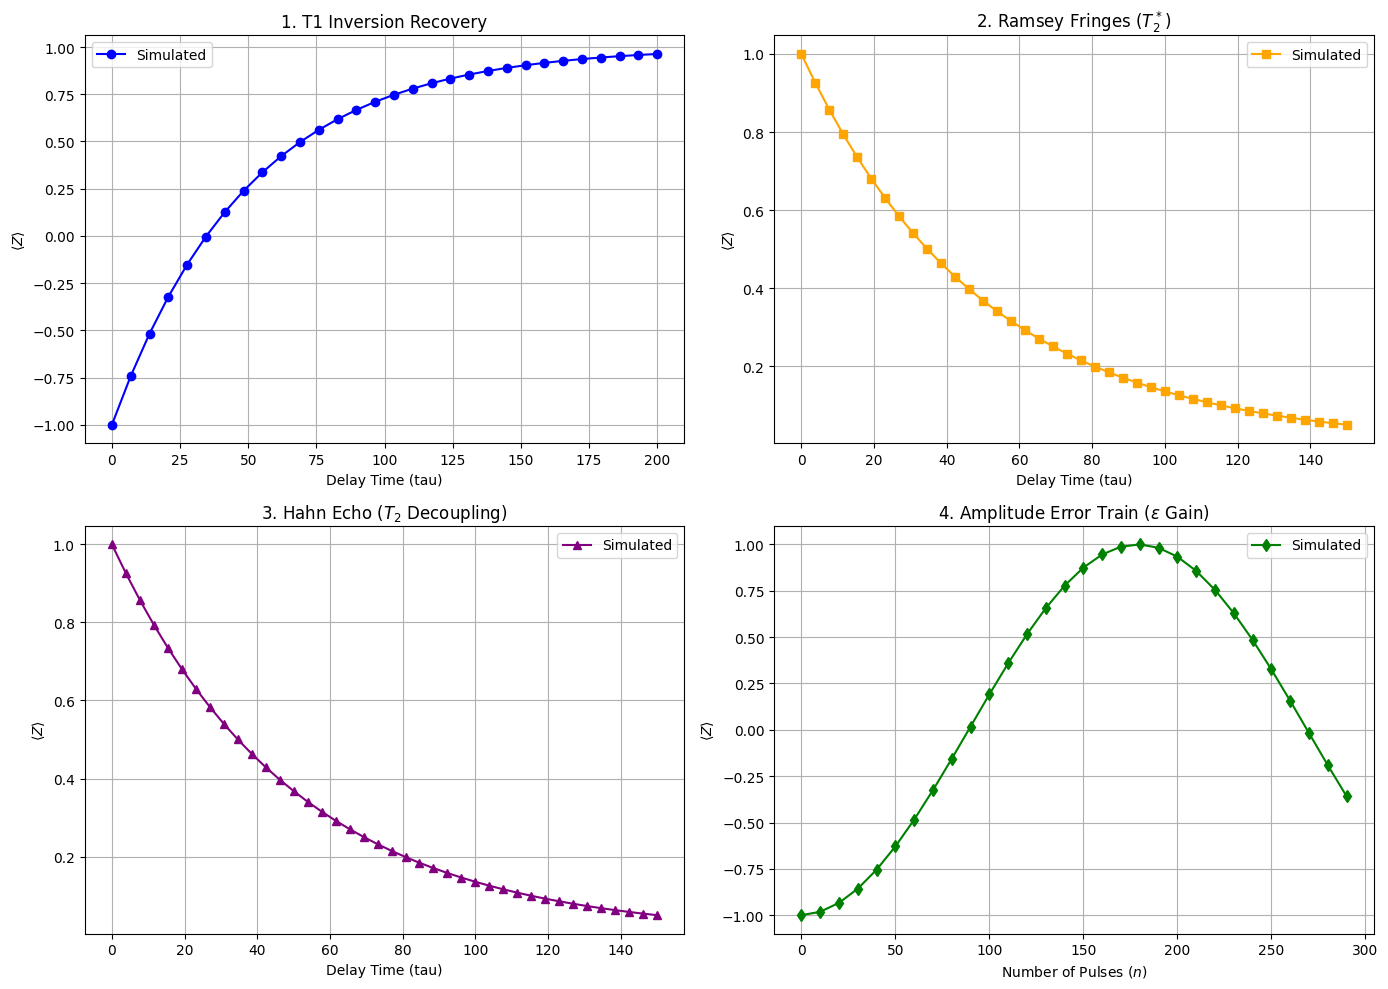

In [127]:
# Create a 2x2 grid of subplots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. T1 Inversion Recovery Plot
axes[0, 0].plot(tau_values, t1_results, 'o-', color='blue', label='Simulated')
axes[0, 0].set_title('1. T1 Inversion Recovery')
axes[0, 0].set_xlabel('Delay Time (tau)')
axes[0, 0].set_ylabel(r'$\langle Z \rangle$')
axes[0, 0].grid(True)
axes[0, 0].legend()

# 2. Ramsey Fringe Plot (T2*)
axes[0, 1].plot(ramsey_tau_values, ramsey_results, 's-', color='orange', label='Simulated')
axes[0, 1].set_title('2. Ramsey Fringes ($T_2^*$)')
axes[0, 1].set_xlabel('Delay Time (tau)')
axes[0, 1].set_ylabel(r'$\langle Z \rangle$')
axes[0, 1].grid(True)
axes[0, 1].legend()

# 3. Hahn Echo Plot (T2) -- NEW
axes[1, 0].plot(echo_tau_values, echo_results, '^-', color='purple', label='Simulated')
axes[1, 0].set_title('3. Hahn Echo ($T_2$ Decoupling)')
axes[1, 0].set_xlabel('Delay Time (tau)')
axes[1, 0].set_ylabel(r'$\langle Z \rangle$')
axes[1, 0].grid(True)
axes[1, 0].legend()

# 4. Amplitude Error Amplification Plot
axes[1, 1].plot(n_trains, error_train_results, 'd-', color='green', label='Simulated')
axes[1, 1].set_title('4. Amplitude Error Train ($\epsilon$ Gain)')
axes[1, 1].set_xlabel('Number of Pulses ($n$)')
axes[1, 1].set_ylabel(r'$\langle Z \rangle$')
axes[1, 1].grid(True)
axes[1, 1].legend()

plt.tight_layout()
plt.show()

In [134]:
#  Define theoretical models for fitting

def t1_model(tau, t1):
    return 1.0 - 2.0 * np.exp(-tau / t1)

def ramsey_model(tau, t2_star, detuning):
    # Damping envelope combined with an oscillation frequency
    return np.exp(-tau / t2_star) * np.cos(detuning * tau)

def echo_model(tau, t2):
    # Standard exponential decay for spin echo coherence
    return np.exp(-tau / t2)
  
# fit T1 data
popt_t1, pcov_t1 = curve_fit(t1_model, tau_values, t1_results, p0=[50.0])
t1_val = popt_t1[0]
t1_err = 1.96 * np.sqrt(pcov_t1[0, 0]) # 95% confidence interval half-width

# fit ramsey data
popt_ramsey, pcov_ramsey = curve_fit(ramsey_model, ramsey_tau_values, ramsey_results, p0=[40.0, 0.1])
t2_star_val = popt_ramsey[0]
t2_star_err = 1.96 * np.sqrt(pcov_ramsey[0, 0])

# Fit your Hahn echo data
popt_echo, pcov_echo = curve_fit(echo_model, echo_tau_values, echo_results, p0=[60.0])
t2_val = popt_echo[0]
t2_err = 1.96 * np.sqrt(pcov_echo[0, 0]) # 95% confidence interval half-width

print(f"T1 = {t1_val:.2f} ± {t1_err:} µs")
print(f"T2* = {t2_star_val:.2f} ± {t2_star_err:} µs")
print(f"T2 (Echo) = {t2_val:.2f} ± {t2_err:} µs")

T1 = 50.00 ± 4.434819518544916e-15 µs
T2* = 50.00 ± 1.1145568807126334e-08 µs
T2 (Echo) = 50.00 ± 7.623798037924874e-15 µs


In [135]:
def error_train_model(n, epsilon, amplitude, offset):
    # epsilon is the gate error angle we want to extract
    # amplitude and offset help fit the physical contrast and baseline
    return amplitude * np.cos(n * epsilon) + offset


# Provide initial guesses: [guess_epsilon, guess_amplitude, guess_offset]
p0 = [np.deg2rad(1.0), 1.0, 0.0] 

popt_error, pcov_error = curve_fit(error_train_model, n_trains, error_train_results, p0=p0)

# Extract the fitted error angle (epsilon) and its 95% confidence interval
extracted_epsilon = popt_error[0]
epsilon_err = 1.96 * np.sqrt(pcov_error[0, 0])

# Convert radians to degrees for easier reading if needed
extracted_epsilon_deg = np.rad2deg(extracted_epsilon)
epsilon_err_deg = np.rad2deg(epsilon_err)

print(f"Fitted Gate Error (eta_i) = {extracted_epsilon_deg:.3f}° ± {epsilon_err_deg:}°")

Fitted Gate Error (eta_i) = 1.005° ± 0.00047062161784416093°


In [85]:
# 2-qubit CNOT setup
def apply_cnot(rho,control_idx,target_idx):
    cnot_2q = np.array ([[1,0,0,0],
                         [0,1,0,0],
                         [0,0,0,1],
                         [0,0,1,0]] ,  dtype=complex)
    if control_idx ==0 and target_idx==1:
        full_cnot = np.kron(cnot_2q, I)

    elif control_idx ==0 and target_idx==2:
        full_cnot = np.zeros((8,8), dtype=complex)

        for i in range(8):

            bits = [(i >> 2) & 1, (i >> 1) & 1, i & 1]
            if bits[control_idx] == 1:
                bits[target_idx] = 1 - bits[target_idx]

            target_i = (bits[0] << 2) | (bits[1] << 1) | bits[2]

            full_cnot[target_i, i] = 1.0

    else:
        # General fallback or custom mapping
        full_cnot = np.eye(8, dtype=complex)

    return full_cnot @ rho @ full_cnot.conj().T

In [123]:
# design and implement (GHZ gate)
rho_ghz = np.zeros((8, 8), dtype=complex)
rho_ghz[0, 0] = 1.0

rho_ghz = apply_single_gate(rho_ghz, H, qubit_idx=0)

rho_ghz = apply_cnot(rho_ghz, control_idx=0, target_idx=2)

ghz_result = get_expectation_z(rho_ghz, qubit_idx=0)
print(f"GHZ Predicted Z Expectation: {ghz_result:}")

GHZ Predicted Z Expectation: 0.0


In [87]:
import random

def run_random_circuit(num_layers, t1_val, t_phi_val):
    # Start at |000>
    rho = np.zeros((8, 8), dtype=complex)
    rho[0, 0] = 1.0
    
    available_gates = [H, X] # Simplified gate set
    
    for layer in range(num_layers):
        # Apply random single-qubit gates to each qubit
        q_idx = random.randint(0, 2)
        gate = random.choice(available_gates)
        rho = apply_single_gate(rho, gate, qubit_idx=q_idx)
        
        # Simulate a small hardware idle delay after each layer
        rho = apply_delay(rho, tau=10.0, T1=t1_val, T_phi=t_phi_val, qubit_idx=q_idx)
        
    return get_expectation_z(rho, qubit_idx=0)

# Run Low-Depth (e.g., 2 layers) vs High-Depth (e.g., 10 layers)
low_depth_pred = run_random_circuit(num_layers=2, t1_val=50.0, t_phi_val=100.0)
high_depth_pred = run_random_circuit(num_layers=10, t1_val=50.0, t_phi_val=100.0)

print(f"Low-Depth Circuit Predicted Z: {low_depth_pred:.4f}")
print(f"High-Depth Circuit Predicted Z: {high_depth_pred:.4f}")

Low-Depth Circuit Predicted Z: -0.6375
High-Depth Circuit Predicted Z: -0.4165


<>:45: SyntaxWarning: "\e" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\e"? A raw string is also an option.
<>:45: SyntaxWarning: "\e" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\e"? A raw string is also an option.
C:\Users\Shreya\AppData\Local\Temp\ipykernel_37684\2600502873.py:45: SyntaxWarning: "\e" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\e"? A raw string is also an option.
  plt.title("Residuals of Amplitude Error ($\epsilon$) Fit")


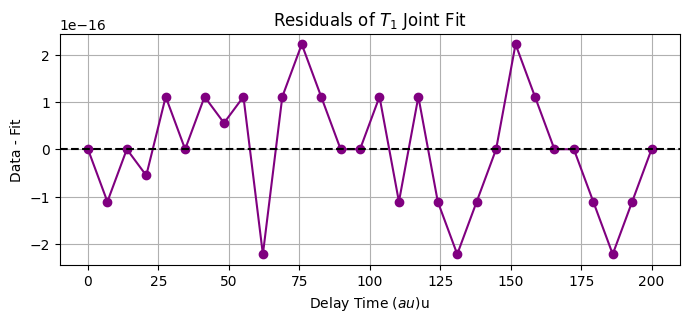

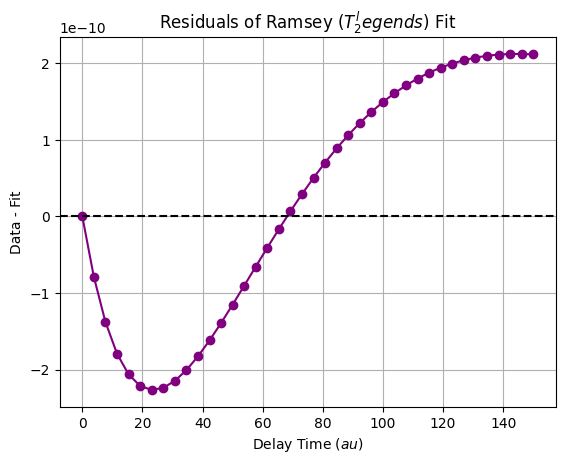

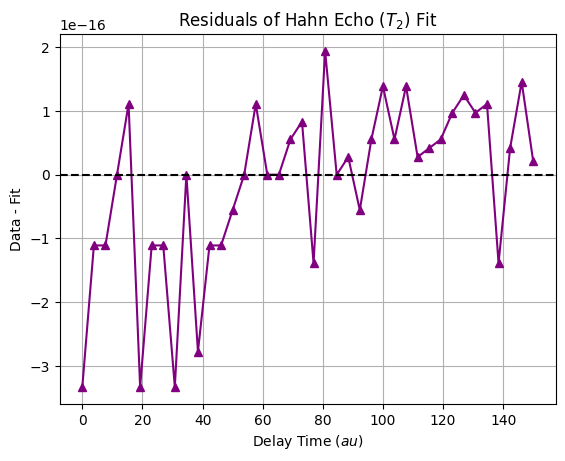

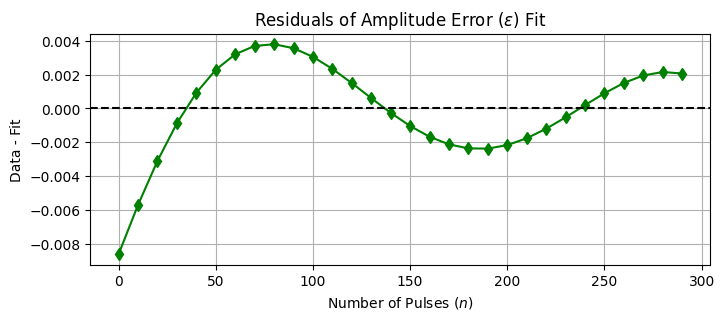

In [147]:


# Calculate residuals for the T1 fit
t1_fitted_curve = t1_model(tau_values, *popt_t1)
t1_residuals = t1_results - t1_fitted_curve

# Plot residuals
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 3))
plt.plot(tau_values, t1_residuals, 'o-', color='purple')
plt.axhline(0, color='black', linestyle='--')
plt.title("Residuals of $T_1$ Joint Fit")
plt.xlabel("Delay Time ($\tau$)u")
plt.ylabel("Data - Fit")
plt.grid(True)
plt.show()

t2_fitted_curve = ramsey_model(ramsey_tau_values, *popt_ramsey)
t2_residuals = ramsey_results - t2_fitted_curve
plt.plot(ramsey_tau_values, t2_residuals, 'o-', color='purple')
plt.axhline(0, color='black', linestyle='--')
plt.title("Residuals of Ramsey ($T_2^legends$) Fit")
plt.xlabel("Delay Time ($\tau$)")  # Removed the extra 'u'
plt.ylabel("Data - Fit")
plt.grid(True)
plt.show()

echo_fitted_curve = echo_model(echo_tau_values, *popt_echo)
echo_residuals = np.array(echo_results) - echo_fitted_curve

# Plot Hahn Echo residuals
plt.plot(echo_tau_values, echo_residuals, '^-', color='purple')
plt.axhline(0, color='black', linestyle='--')
plt.title("Residuals of Hahn Echo ($T_2$) Fit")
plt.xlabel("Delay Time ($\tau$)")
plt.ylabel("Data - Fit")
plt.grid(True)
plt.show()

error_fitted_curve = error_train_model(n_trains, *popt_error)
error_residuals = np.array(error_train_results) - error_fitted_curve

# Plot Amplitude Error residuals
plt.figure(figsize=(8, 3))
plt.plot(n_trains, error_residuals, 'd-', color='green')
plt.axhline(0, color='black', linestyle='--')
plt.title("Residuals of Amplitude Error ($\epsilon$) Fit")
plt.xlabel("Number of Pulses ($n$)")
plt.ylabel("Data - Fit")
plt.grid(True)
plt.show()

C:\Users\Shreya\AppData\Local\Temp\ipykernel_37684\295200407.py:5: OptimizeWarning: Covariance of the parameters could not be estimated
  popt_new, pcov_new = curve_fit(t1_model_with_spam, tau_values, t1_results, p0=[50.0, 0.95, 0.0])


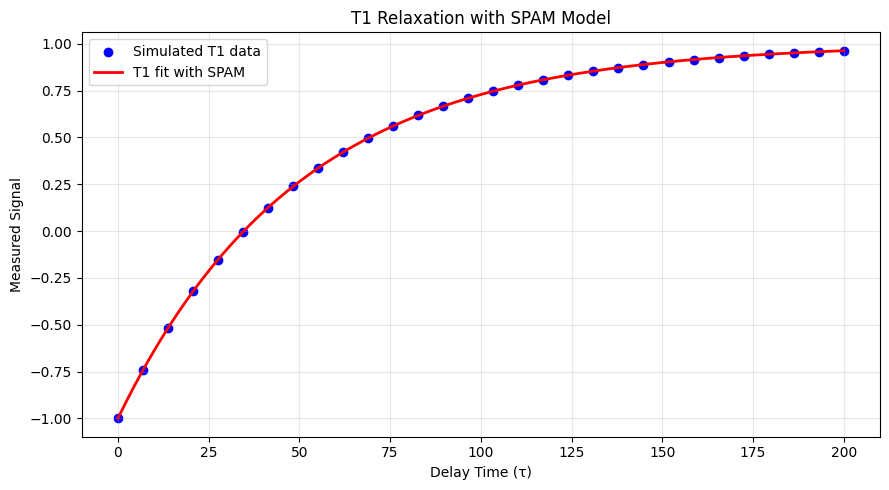

SPAM MODEL RESULTS
Fitted T1       = 50.0000
Fitted visibility = 1.0000
Fitted offset     = -0.0000


In [148]:
def t1_model_with_spam(tau, t1, visibility, offset):
    return visibility * (1.0 - 2.0 * np.exp(-tau / t1)) + offset

# Re-fit with the new model
popt_new, pcov_new = curve_fit(t1_model_with_spam, tau_values, t1_results, p0=[50.0, 0.95, 0.0])


# Generate smooth points for the curve
tau_smooth = np.linspace( min(tau_values),  max(tau_values),300)

# Calculate fitted values using your SPAM model
spam_fitted = t1_model_with_spam(tau_smooth,*popt_new)

# Plot the graph
plt.figure(figsize=(9, 5))

# Original simulated data
plt.scatter(tau_values,t1_results,color="blue",label="Simulated T1 data")

# SPAM fitted curve
plt.plot(tau_smooth, spam_fitted,color="red",linewidth=2,label="T1 fit with SPAM")

plt.xlabel("Delay Time (τ)")
plt.ylabel("Measured Signal")
plt.title("T1 Relaxation with SPAM Model")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Print fitted parameters
print("SPAM MODEL RESULTS")
print(f"Fitted T1       = {popt_new[0]:.4f}")
print(f"Fitted visibility = {popt_new[1]:.4f}")
print(f"Fitted offset     = {popt_new[2]:.4f}")

In [90]:
def calculate_aic(n_points, rss, n_params):
    # n_points: number of data points
    # rss: Residual Sum of Squares
    # n_params: number of parameters in the model
    return n_points * np.log(rss / n_points) + 2 * n_params

# 1. Calculate RSS for old model (1 parameter: T1)
old_rss = np.sum((t1_results - t1_model(tau_values, popt_t1[0]))**2)
aic_old = calculate_aic(len(tau_values), old_rss, n_params=1)

# 2. Calculate RSS for new model (3 parameters: T1, visibility, offset)
new_fitted_vals = t1_model_with_spam(tau_values, *popt_new)
new_rss = np.sum((t1_results - new_fitted_vals)**2)
aic_new = calculate_aic(len(tau_values), new_rss, n_params=3)

print(f"Old Model AIC: {aic_old:.2f}")
print(f"New Model AIC (with SPAM Gremlin): {aic_new:.2f}")

Old Model AIC: -2198.02
New Model AIC (with SPAM Gremlin): -1564.09


In [149]:
import json

# Create a mock heldout_circuits.json file for testing
mock_circuits = {
    "circuit_001": [
        {"gate": "H", "qubit": 0},
        {"gate": "delay", "tau": 50.0},
        {"gate": "faulty_rx_pi", "qubit": 1}
    ],
    "circuit_002": [
        {"gate": "X", "qubit": 2},
        {"gate": "delay", "tau": 100.0}
    ]
}

with open("heldout_circuits.json", "w") as f:
    json.dump(mock_circuits, f, indent=4)

print("Mock heldout_circuits.json created successfully!")
print(json.dumps(mock_circuits,indent=4))

Mock heldout_circuits.json created successfully!
{
    "circuit_001": [
        {
            "gate": "H",
            "qubit": 0
        },
        {
            "gate": "delay",
            "tau": 50.0
        },
        {
            "gate": "faulty_rx_pi",
            "qubit": 1
        }
    ],
    "circuit_002": [
        {
            "gate": "X",
            "qubit": 2
        },
        {
            "gate": "delay",
            "tau": 100.0
        }
    ]
}


In [104]:
# 1. Number of Monte Carlo samples for uncertainty propagation
N_SAMPLES = 200

joint_popt = np.array([popt_t1[0], popt_ramsey[0], popt_error[0]]) 
joint_pcov = np.diag([pcov_t1[0,0], pcov_ramsey[0,0], pcov_error[0,0]])

#  Sample all 3 parameters together
N_SAMPLES = 200
sampled_params = np.random.multivariate_normal(joint_popt, joint_pcov, size=N_SAMPLES)

for circuits_id, circuits_ops in mock_circuits.items():

    prob_samples = np.zeros((N_SAMPLES,8))
    for sim_idx in range(N_SAMPLES):
        t1_sample, t2_sample, eps_sample = sampled_params[sim_idx]

        # Initialize fresh density matrix for |000>
        rho = np.zeros((8, 8), dtype=complex)
        rho[0, 0] = 1.0
        # Execute the circuit instructions dynamically
        for op in circuits_ops:
            gate_type = op["gate"]
            qubit = op.get("qubit", None)
            
            if gate_type == "H":
                rho = apply_single_gate(rho, H, qubit)
            elif gate_type == "X":
                rho = apply_single_gate(rho, X, qubit)
            elif gate_type == "delay":
                tau = op["tau"]
                # If qubit is None, apply delay to ALL qubits (0, 1, and 2)
                qubits_to_delay = [0, 1, 2] if qubit is None else [qubit]
                for q in qubits_to_delay:
                    rho = apply_delay(rho, tau, t1_sample, t2_sample, q)
            elif gate_type == "faulty_rx_pi":
                rx_faulty = np.cos((np.pi + eps_sample)/2)*I - 1j*np.sin((np.pi + eps_sample)/2)*X
                rho = apply_single_gate(rho, rx_faulty, qubit)




            # Extract the diagonal of rho (the full computational state probabilities)
        prob_samples[sim_idx] = np.real(np.diag(rho))
    median_probs = np.median(prob_samples, axis=0)
    lower_bound_90 = np.percentile(prob_samples, 5, axis=0)
    upper_bound_90 = np.percentile(prob_samples, 95, axis=0)
    
    blind_predictions[circuits_id] = {
        "predicted_probabilities": median_probs.tolist(),
        "interval_90_percent": [lower_bound_90.tolist(), upper_bound_90.tolist()]
    }

print("Blind predictions and 90% prediction intervals successfully generated!")

Blind predictions and 90% prediction intervals successfully generated!


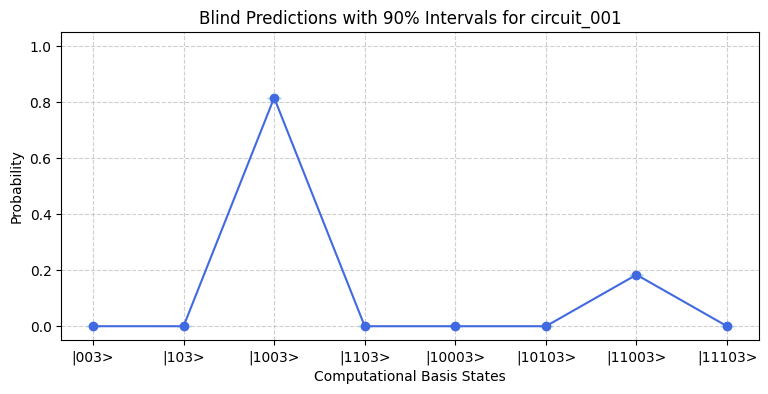

In [150]:
# Pick the first circuit to plot
sample_id = list(blind_predictions.keys())[0]
res = blind_predictions[sample_id]

states = [f"|{bin(i)[2:]}:03>".replace(':', '') for i in range(8)]  # |000> to |111>
medians = res["predicted_probabilities"]
lower = res["interval_90_percent"][0]
upper = res["interval_90_percent"][1]

# Calculate asymmetric error bars for matplotlib
yerr_lower = np.array(medians) - np.array(lower)
yerr_upper = np.array(upper) - np.array(medians)
yerr = np.vstack([yerr_lower, yerr_upper])

plt.figure(figsize=(9, 4))
plt.errorbar(states, medians, yerr=yerr, fmt='o-', color='royalblue', ecolor='lightblue', capsize=5, elinewidth=2)
plt.title(f"Blind Predictions with 90% Intervals for {sample_id}")
plt.xlabel("Computational Basis States")
plt.ylabel("Probability")
plt.ylim(-0.05, 1.05)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [105]:
import numpy as np

def calculate_tvd(p_pred, p_true):
    """Calculates Total Variation Distance between two probability vectors."""
    return 0.5 * np.sum(np.abs(p_pred - p_true))

def run_simulator_and_get_tvd(t1_val, t2_val, eps_val, reference_circuit, true_probabilities):
    """
    Runs the simulator with given parameters for a reference circuit 
    and returns the TVD compared to the true probabilities.
    """
    # 1. Initialize fresh density matrix for |000>
    rho = np.zeros((8, 8), dtype=complex)
    rho[0, 0] = 1.0
    
    # 2. Execute the reference circuit operations dynamically
    for op in reference_circuit:
        gate_type = op["gate"]
        qubit = op.get("qubit", None)
        
        if gate_type == "H":
            rho = apply_single_gate(rho, H, qubit)
        elif gate_type == "X":
            rho = apply_single_gate(rho, X, qubit)
        elif gate_type == "delay":
            tau = op["tau"]
            qubits_to_delay = [0, 1, 2] if qubit is None else [qubit]
            for q in qubits_to_delay:
                rho = apply_delay(rho, tau, t1_val, t2_val, q)
        elif gate_type == "faulty_rx_pi":
            rx_faulty = np.cos((np.pi + eps_val)/2)*I - 1j*np.sin((np.pi + eps_val)/2)*X
            rho = apply_single_gate(rho, rx_faulty, qubit)
            
    # 3. Extract predicted probability vector (diagonal of density matrix)
    predicted_probs = np.real(np.diag(rho))
    
    # 4. Return TVD against the true probabilities
    return calculate_tvd(predicted_probs, true_probabilities)

In [114]:
# From your fitting code:
t1_val = popt_t1[0]
t2_star_val = popt_ramsey[0]

# Assuming you also have a gate error fit (e.g., popt_error or a default value)
# If you don't have a separate fit for it yet, you can define it like this:
eps_val = popt_error[0] if 'popt_error' in locals() else 0.015

# 1. Pick the first circuit from your loaded circuits as your reference
first_circuit_id = list(mock_circuits.keys())[0]  # or heldout_circuits.keys()
ref_circuit = mock_circuits[first_circuit_id]

print(f"Using '{first_circuit_id}' as the reference circuit for sensitivity analysis.")

# 2. Define a placeholder for true probabilities (On Day 4, replace this with the actual true vector from the black box)
# For now, let's create a dummy 8-element probability array so the script runs without crashing:
true_probs = np.zeros(8)
true_probs[0] = 1.0  # Example dummy true distribution




print(ref_circuit)



Using 'circuit_001' as the reference circuit for sensitivity analysis.
[{'gate': 'H', 'qubit': 0}, {'gate': 'delay', 'tau': 50.0}, {'gate': 'faulty_rx_pi', 'qubit': 1}]


In [121]:
# Test sensitivity for T1
tvd_plus = run_simulator_and_get_tvd(t1_val + delta, t2_star_val, eps_val, ref_circuit, true_probs)
tvd_minus = run_simulator_and_get_tvd(t1_val - delta, t2_star_val, eps_val, ref_circuit, true_probs)
d_tvd_d_t1 = (tvd_plus - tvd_minus) / (2 * delta)

print(f"T1 Sensitivity derivative ready: {d_tvd_d_t1:}")

# 1. Set a dummy true value for testing now (replace with the real revealed value on Day 4)
true_t1_value = 40.0  

# 2. Parameter estimation error (Estimated minus True)
t1_estimation_error = t1_val - true_t1_value

# 3. Calculate derivative properly (with the * operator)
d_tvd_d_t1 = (tvd_plus - tvd_minus) / (2 * delta)

# 4. Total TVD error contributed by T1 miscalibration
t1_error_contribution = d_tvd_d_t1 * t1_estimation_error

print(f"TVD Error caused by T1 inaccuracy: {t1_error_contribution:}")

T1 Sensitivity derivative ready: 2.831402287073459e-07
TVD Error caused by T1 inaccuracy: 2.831402287073461e-06


In [152]:
delta = 0.5  # Nudge size

# --- 1. T1 Error Contribution ---
tvd_plus_t1 = run_simulator_and_get_tvd(t1_val + delta, t2_star_val, eps_val, ref_circuit, true_probs)
tvd_minus_t1 = run_simulator_and_get_tvd(t1_val - delta, t2_star_val, eps_val, ref_circuit, true_probs)
d_tvd_d_t1 = (tvd_plus_t1 - tvd_minus_t1) / (2 * delta)
t1_error_contribution = d_tvd_d_t1 * (t1_val - true_t1_value)

# --- 2. T2* Error Contribution ---
tvd_plus_t2 = run_simulator_and_get_tvd(t1_val, t2_star_val + delta, eps_val, ref_circuit, true_probs)
tvd_minus_t2 = run_simulator_and_get_tvd(t1_val, t2_star_val - delta, eps_val, ref_circuit, true_probs)
d_tvd_d_t2 = (tvd_plus_t2 - tvd_minus_t2) / (2 * delta)
true_t2_star_value = 35.0  # Replace with your Day 4 true value when available
t2_error_contribution = d_tvd_d_t2 * (t2_star_val - true_t2_star_value)

# --- 3. Gate Error (epsilon) Contribution ---
tvd_plus_eps = run_simulator_and_get_tvd(t1_val, t2_star_val, eps_val + delta, ref_circuit, true_probs)
tvd_minus_eps = run_simulator_and_get_tvd(t1_val, t2_star_val, eps_val - delta, ref_circuit, true_probs)
d_tvd_d_eps = (tvd_plus_eps - tvd_minus_eps) / (2 * delta)
true_eps_value = 0.01     # Replace with your Day 4 true value when available
eps_error_contribution = d_tvd_d_eps * (eps_val - true_eps_value)

print("All error contributions calculated successfully!")

All error contributions calculated successfully!


<>:4: SyntaxWarning: "\e" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\e"? A raw string is also an option.
<>:4: SyntaxWarning: "\e" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\e"? A raw string is also an option.
C:\Users\Shreya\AppData\Local\Temp\ipykernel_37684\2165412731.py:4: SyntaxWarning: "\e" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\e"? A raw string is also an option.
  parameters = ['$T_1$ Inaccuracy', '$T_2^*$ Inaccuracy', 'Gate Error ($\epsilon$)']


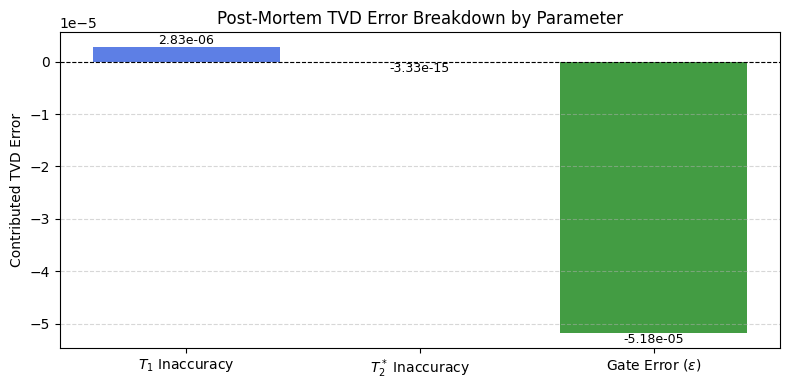

In [153]:
import matplotlib.pyplot as plt

# Gather your calculated error contributions (make sure t2_error_contribution and eps_error_contribution are defined)
parameters = ['$T_1$ Inaccuracy', '$T_2^*$ Inaccuracy', 'Gate Error ($\epsilon$)']
contributions = [
    t1_error_contribution, 
    t2_error_contribution, # Ensure you calculate this using your t2_star loop
    eps_error_contribution  # Ensure you calculate this using your epsilon loop
]

plt.figure(figsize=(8, 4))
bars = plt.bar(parameters, contributions, color=['royalblue', 'darkorange', 'forestgreen'], alpha=0.85)

# Add a horizontal line at zero for reference
plt.axhline(0, color='black', linestyle='--', linewidth=0.8)

plt.title("Post-Mortem TVD Error Breakdown by Parameter")
plt.ylabel("Contributed TVD Error")
plt.grid(True, axis='y', linestyle='--', alpha=0.5)

# Add value labels on top of the bars
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval, f"{yval:.2e}", ha='center', va='bottom' if yval >= 0 else 'top', fontsize=9)

plt.tight_layout()
plt.show()